# Exp 11: sanity check with linear collection costs

In [1]:
from pathlib import Path
import gzip
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
from matplotlib.lines import Line2D
import subprocess
import sys

In [2]:
RESULTS_11 = Path("../results/exp_11")
RESULTS_10 = Path("../results/exp_10")
FIG_DIR = Path("../figures/exp_11")
FIG_DIR.mkdir(parents=True, exist_ok=True)

ARMS = ["zero", "star", "road"]          # road = exp_10, the real road tree
ARM_LABELS = {"zero": "zero cost (linear c_f = 0)", "star": "star (linear c_f)", "road": "road (exp_10)"}
PROFIT_TOL = 1e-6                        # relative
SWITCH_TOL = 1e-6                        # a prediction "inside" a bracket, up to rounding

# light-mode chart tokens; categorical slots 1-3 validate all-pairs (aqua is sub-3:1, so
# every chart also has a legend and a table view)
SURFACE, INK, INK_SECONDARY, INK_MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
ARM_COLORS = {"zero": "#2a78d6", "star": "#eb6834", "road": "#1baf7a"}
MATCH_NONE, MATCH_SOME, MATCH_ALL = GRID, "#86b6ef", "#184f95"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK_SECONDARY, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "xtick.labelcolor": INK_SECONDARY, "ytick.labelcolor": INK_SECONDARY,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8, "legend.frameon": False,
})

In [3]:
def load_jobs(paths, arm_of):
    jobs = []
    for file in sorted(paths):
        with gzip.open(file, "rt", encoding="utf-8") as f:
            jobs.append((arm_of(file), json.load(f)))
    return jobs

jobs = load_jobs(RESULTS_11.rglob("*.json.gz"), lambda file: file.parent.parent.name)
instances_11 = {payload["instance_id"] for _, payload in jobs}
# exp_10 counterparts, for the same instances only
jobs += [
    (arm, payload)
    for arm, payload in load_jobs(RESULTS_10.rglob("*.json.gz"), lambda file: "road")
    if payload["instance_id"] in instances_11
]

windows, cost_rows, point_rows = {}, [], []
for arm, payload in jobs:
    instance_id = payload["instance_id"]
    windows[instance_id] = payload["window"]
    sigma_ell = payload["experiment_metadata"]["constants"]["sigma_ell"]
    high_ids = set(payload["high_ids"])
    if arm != "road":
        costs = payload["collection_costs"]
        cost_rows.append({"arm": arm, "instance": instance_id, "n_runs": payload["n_runs"],
                          **{k: v for k, v in costs.items() if k not in ("c_f", "routing_mode")}})
    for run in payload["runs"]:
        primary = run["summary"]["platform_solve_result"]["primary_result"]
        matched = set(primary["selected_intermediaries"])
        point_rows.append({
            "arm": arm, "instance": instance_id, "eps_h": run["eps_h"], "phase": run["phase"].split("_")[0],
            "n_high": len(matched & high_ids), "n_low": len(matched - high_ids),
            "profit": primary["platform_profit"], "sigma_ell": sigma_ell,
            "wall_time": run["wall_time"], "rel_gap": run["summary"]["rel_gap"],
        })

points = pd.DataFrame(point_rows).sort_values(["instance", "arm", "eps_h"]).reset_index(drop=True)
print(f"{len(jobs)} jobs: " + ", ".join(f"{arm} {n}" for arm, n in pd.Series([a for a, _ in jobs]).value_counts().items()))
print(f"instances: {sorted(instances_11)}; {len(points)} solved points; max rel_gap {points['rel_gap'].max():.1e}")
points.groupby("arm")["wall_time"].describe()[["count", "mean", "50%", "max"]]

132 jobs: star 44, zero 44, road 44
instances: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44]; 4727 solved points; max rel_gap 4.4e-05


,count,mean,50%,max
arm,,,,
road,1633.0,203.706963,144.359121,1292.018032
star,1552.0,101.631830,84.571517,867.966729
zero,1542.0,101.662031,94.135615,516.972929


In [4]:
def thresholds(w):
    # Prop 3 window (cases ii-iii) and the saturated threshold (EC4, cases iv-v), in tons
    a = w["n_l"] + w["eps_l"]
    L = w["K"] - w["n_h"]
    M = w["T_l"] * w["n_l"] / w["T_h"]
    rho = w["sigma_h"] / w["sigma_l"]
    disc = (M + a) ** 2 - 4 * M * rho * a
    lo, hi = ((M + a - np.sqrt(disc)) / 2, (M + a + np.sqrt(disc)) / 2) if disc >= 0 else (np.nan, np.nan)

    K, n_h, n_l, T_h, T_l = w["K"], w["n_h"], w["n_l"], w["T_h"], w["T_l"]
    s_l, s_h = w["sigma_l"], w["sigma_h"]
    F = T_l * n_l + T_h * n_h
    e_l = s_l / a
    eps_l_s = K * (F - T_h * K) * s_l / (F * s_h - T_h * K * s_l) - n_l
    bar = min(L + n_h * (s_h - s_l) / (K * e_l - s_l),
              T_l * n_l * s_h / ((F - T_h * K) * e_l + T_h * s_l)) if w["eps_l"] < eps_l_s else np.inf
    return {"L": L, "eps_h_minus": lo, "eps_h_plus": hi, "eps_h_bar": bar}

pred = pd.DataFrame({i: thresholds(w) for i, w in windows.items()}).T
pred.index.name = "instance"
pred.round(4)

,L,eps_h_minus,eps_h_plus,eps_h_bar
instance,,,,
1,7.0,4.2958,6.7042,7.2000
2,7.0,5.1056,6.8944,7.0400
3,9.0,4.6972,8.3028,inf
4,9.0,6.3820,8.6180,9.1667
5,5.0,3.3675,4.6325,5.2000
6,6.0,3.0682,5.9318,6.0667
7,7.0,3.3875,6.6125,inf
8,7.0,4.2958,6.7042,inf
9,7.0,5.1056,6.8944,7.0400


In [5]:
TIE_TOL = 1e-7  # relative; compositions within this of the best are all optimal


def profit_closed_form(w, eps_h, x_h):
    # (S-PFP) profit in sigma_l units with x_h high types matched: max over vbar of (EC9)
    K, n_h, n_l, eps_l, T_h, T_l = (float(w[c]) for c in ["K", "n_h", "n_l", "eps_l", "T_h", "T_l"])
    s_l, s_h, N = float(w["sigma_l"]), float(w["sigma_h"]), float(w["min_trucks"])
    F = T_l * n_l + T_h * n_h
    A_l, A_h = n_l + eps_l, min(n_h + eps_h, K)
    delta = max(0.0, n_h + eps_h - K) / min(n_h, K - eps_h)

    def Pi(v):
        return (F * v - T_l * max(A_l * v - s_l, 0) - (T_h + delta * (T_h - x_h)) * max(A_h * v - s_h, 0)
                - (N - x_h) * s_l - x_h * s_h)

    upper = s_h / eps_h if x_h < T_h and eps_h > 0 else np.inf
    return max(Pi(v) for v in (s_l / A_l, s_h / A_h, upper) if 0 <= v <= upper)


def model_optimum(w, eps_h):
    # optimal profit and every optimal composition [n_high, n_low]
    T_h, N = int(w["T_h"]), int(w["min_trucks"])
    values = {x_h: profit_closed_form(w, eps_h, x_h) for x_h in range(T_h + 1)}
    best = max(values.values())
    optimal = [[x_h, N - x_h] for x_h, v in values.items() if v >= best - TIE_TOL * max(1.0, abs(best))]
    return best, optimal


rows = []
for r in points.itertuples():
    best, optimal = model_optimum(windows[r.instance], r.eps_h)
    rows.append({
        "model_optimal": optimal,
        "tie": len(optimal) > 1,
        "matched_ok": [r.n_high, r.n_low] in optimal,
        "model_profit": best * r.sigma_ell,
    })

points = pd.concat([points.drop(columns=[c for c in ["model_optimal", "tie", "matched_ok", "model_profit"] if c in points]),
                    pd.DataFrame(rows, index=points.index)], axis=1)
points["profit_rel_err"] = (points["profit"] - points["model_profit"]).abs() / points["model_profit"].abs().clip(lower=1.0)
points["profit_ok"] = points["profit_rel_err"] <= PROFIT_TOL

summary = points.groupby("arm").agg(
    points=("eps_h", "size"),
    matched_ok=("matched_ok", "mean"),
    profit_ok=("profit_ok", "mean"),
    max_profit_rel_err=("profit_rel_err", "max"),
    ties=("tie", "sum"),
).reindex([a for a in ARMS if a in points["arm"].unique()])
summary

,points,matched_ok,profit_ok,max_profit_rel_err,ties
arm,,,,,
zero,1542,1.000000,1.000000,4.434821e-08,84
star,1552,1.000000,1.000000,3.015759e-08,93
road,1633,0.736069,0.004287,2.803693e+05,85


In [6]:
print("Linear-cost points that fail either check:")
points.query("arm != 'road' and (not matched_ok or not profit_ok)")[
    ["arm", "instance", "eps_h", "phase", "n_high", "n_low", "model_optimal", "profit", "model_profit", "profit_rel_err"]
]

Linear-cost points that fail either check:


,arm,instance,eps_h,phase,n_high,n_low,model_optimal,profit,model_profit,profit_rel_err


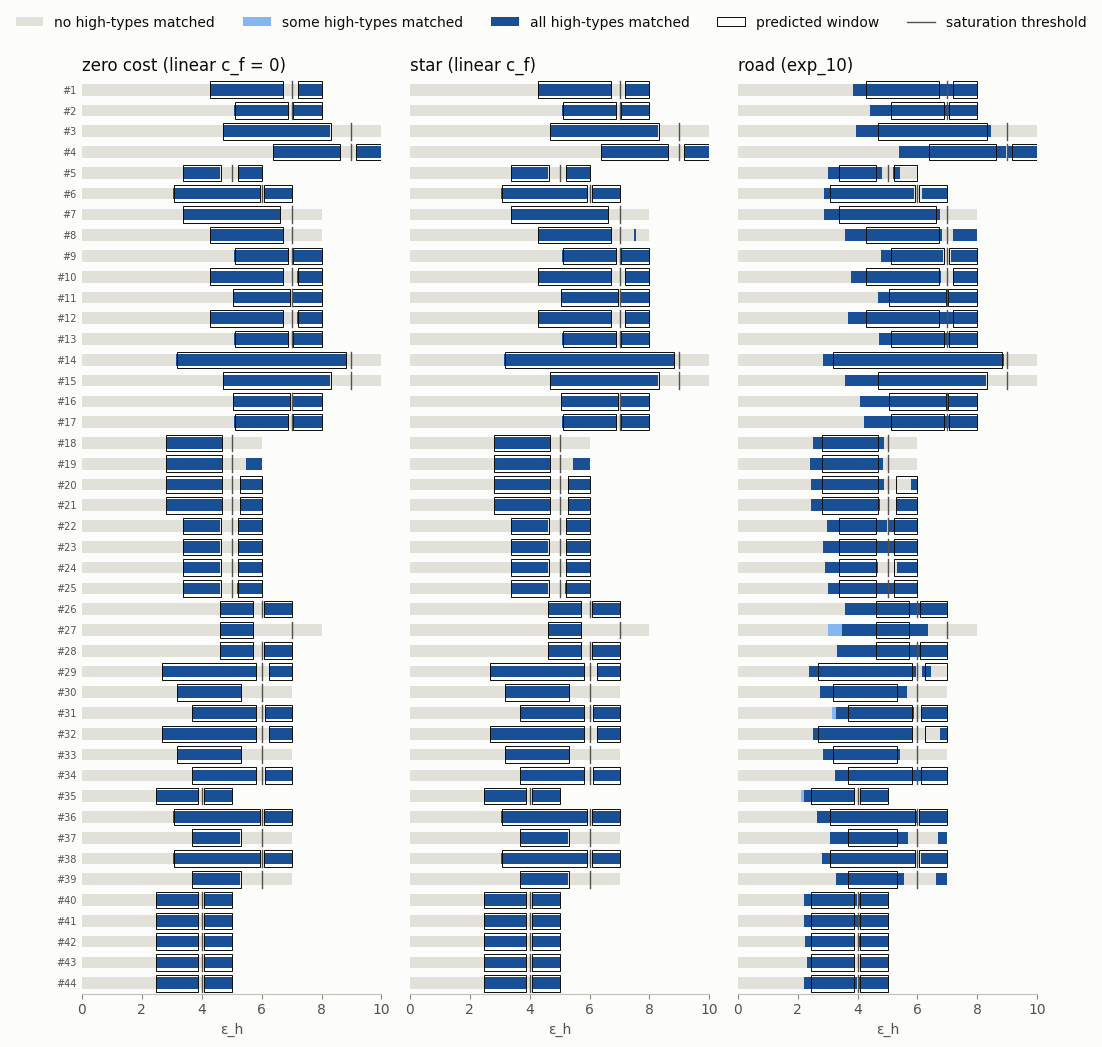

In [7]:
arms_present = [a for a in ARMS if a in set(points["arm"])]
order = pred.index.tolist()
y_of = {i: n for n, i in enumerate(order)}
x_max = points["eps_h"].max()

fig, axes = plt.subplots(1, len(arms_present), figsize=(3.4 * len(arms_present), 0.2 * len(order) + 1.3),
                         sharex=True, sharey=True, squeeze=False)
strip_h, box_h = 0.56, 0.8
for ax, arm in zip(axes.flat, arms_present):
    for instance_id, g in points[points["arm"] == arm].groupby("instance"):
        y, T_h, p = y_of[instance_id], windows[instance_id]["T_h"], pred.loc[instance_id]
        eps = g["eps_h"].to_numpy()
        edges = np.concatenate([[eps[0]], (eps[1:] + eps[:-1]) / 2, [eps[-1]]])
        for (x0, x1), k in zip(zip(edges[:-1], edges[1:]), g["n_high"]):
            color = MATCH_NONE if k == 0 else (MATCH_ALL if k == T_h else MATCH_SOME)
            ax.add_patch(Rectangle((x0, y - strip_h / 2), x1 - x0, strip_h, facecolor=color, edgecolor="none"))
        regions = [(p["eps_h_minus"], min(p["eps_h_plus"], p["L"]))]
        if np.isfinite(p["eps_h_bar"]):
            regions.append((max(p["eps_h_bar"], p["L"]), eps[-1]))
        for lo, hi in regions:
            if hi > lo:
                ax.add_patch(Rectangle((lo, y - box_h / 2), hi - lo, box_h, facecolor="none", edgecolor=INK, linewidth=0.7))
        ax.plot([p["L"]] * 2, [y - box_h / 2, y + box_h / 2], color=INK_SECONDARY, linewidth=1.0)
    ax.set_xlim(0, x_max)
    ax.set_title(ARM_LABELS[arm], loc="left", color=INK)
    ax.set_xlabel("ε_h")
    ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False)

axes.flat[0].set_ylim(len(order) - 0.5, -0.5)
axes.flat[0].set_yticks(range(len(order)))
axes.flat[0].set_yticklabels([f"#{i}" for i in order], fontsize=7)
fig.legend(handles=[
    Patch(facecolor=MATCH_NONE, label="no high-types matched"),
    Patch(facecolor=MATCH_SOME, label="some high-types matched"),
    Patch(facecolor=MATCH_ALL, label="all high-types matched"),
    Patch(facecolor="none", edgecolor=INK, linewidth=0.7, label="predicted window"),
    Line2D([], [], color=INK_SECONDARY, linewidth=1.0, label="saturation threshold"),
], loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=5)

plt.tight_layout()
plt.savefig(FIG_DIR / "window_overview.png", bbox_inches="tight", dpi=300)
plt.show()

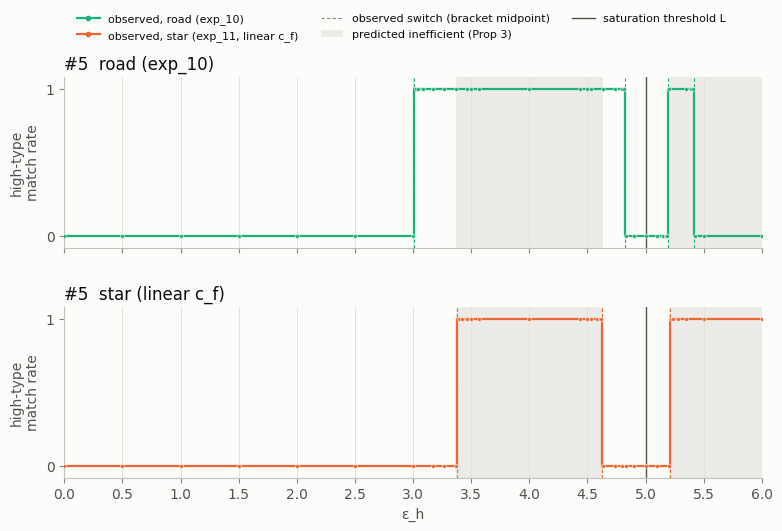

In [8]:
# Instance #5: high-type match rate vs. ε_h, road (exp_10) vs. star (exp_11), in the style of exp_10's sweep plot
I = 5
PREDICTED_FILL = "#ecebe7"
w, pr = windows[I], pred.loc[I]
arms_5 = [a for a in ["road", "star"] if a in set(points.query("instance == @I")["arm"])]

fig, axes = plt.subplots(len(arms_5), 1, figsize=(9, 2.3 * len(arms_5) + 0.6), sharex=True, squeeze=False,
                         gridspec_kw={"hspace": 0.35})
x_max = points.query("instance == @I")["eps_h"].max()
for ax, arm in zip(axes[:, 0], arms_5):
    g = points.query("instance == @I and arm == @arm").sort_values("eps_h")
    eps, rate = g["eps_h"].to_numpy(), (g["n_high"] / w["T_h"]).to_numpy()

    # predicted inefficient regions: the window (ε_h⁻, min(ε_h⁺, L)) and, past L, (ε̄_h, ∞)
    ax.axvspan(pr["eps_h_minus"], min(pr["eps_h_plus"], pr["L"]), color=PREDICTED_FILL, linewidth=0, zorder=0)
    if np.isfinite(pr["eps_h_bar"]):
        ax.axvspan(max(pr["eps_h_bar"], pr["L"]), x_max, color=PREDICTED_FILL, linewidth=0, zorder=0)
    ax.axvline(pr["L"], color=INK_SECONDARY, linewidth=1.0, zorder=1)

    # observed match rate: steps between solved points, and the points themselves
    ax.step(eps, rate, where="mid", color=ARM_COLORS[arm], linewidth=1.6, zorder=2)
    ax.plot(eps, rate, "o", color=ARM_COLORS[arm], markersize=2.8, markeredgecolor=SURFACE, markeredgewidth=0.4, zorder=3)

    # observed switches: bracket midpoint, labelled
    on = rate > 0
    for k in np.flatnonzero(on[1:] != on[:-1]):
        mid = (eps[k] + eps[k + 1]) / 2
        ax.axvline(mid, color=ARM_COLORS[arm], linewidth=0.8, linestyle=(0, (3, 2)), zorder=1)

    ax.set_ylim(-0.08, 1.08)
    ax.set_yticks([0, 1])
    ax.set_ylabel("high-type\nmatch rate")
    ax.set_title(f"#{I}  {ARM_LABELS[arm]}", loc="left", color=INK)
    ax.grid(axis="x", color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)

axes[-1, 0].set_xlabel("ε_h")
axes[-1, 0].set_xlim(0, x_max)
axes[-1, 0].set_xticks(np.arange(0, x_max + 1e-9, 0.5))

fig.legend(handles=[
    Line2D([], [], color=ARM_COLORS["road"], marker="o", markersize=3, linewidth=1.6, label="observed, road (exp_10)"),
    Line2D([], [], color=ARM_COLORS["star"], marker="o", markersize=3, linewidth=1.6, label="observed, star (exp_11, linear c_f)"),
    Line2D([], [], color=INK_MUTED, linewidth=0.8, linestyle=(0, (3, 2)), label="observed switch (bracket midpoint)"),
    Patch(facecolor=PREDICTED_FILL, label="predicted inefficient (Prop 3)"),
    Line2D([], [], color=INK_SECONDARY, linewidth=1.0, label="saturation threshold L"),
], loc="lower center", bbox_to_anchor=(0.5, 0.93), ncol=3, fontsize=8)
plt.savefig(FIG_DIR / f"match_rate_{I}.png", bbox_inches="tight", dpi=300)
plt.show()


In [9]:
# Linear-cost points where high types are matched outside the predicted inefficient regions: are they ties?
def in_predicted_region(instance_id, eps_h):
    p = pred.loc[instance_id]
    if p["eps_h_minus"] - SWITCH_TOL <= eps_h <= min(p["eps_h_plus"], p["L"]) + SWITCH_TOL:
        return True
    return bool(np.isfinite(p["eps_h_bar"]) and eps_h >= max(p["eps_h_bar"], p["L"]) - SWITCH_TOL)

linear = points.query("arm != 'road' and n_high > 0")
unpredicted = linear[[not in_predicted_region(r.instance, r.eps_h) for r in linear.itertuples()]]
print("High types matched outside the predicted regions (linear-cost arms):")
display(unpredicted.groupby(["arm", "instance"]).agg(
    points=("eps_h", "size"), eps_from=("eps_h", "min"), eps_to=("eps_h", "max"),
    all_ties=("tie", "all"), all_matched_ok=("matched_ok", "all")))

# #19: knife edge eps_l = eps_l^s, so (EC4) gives eps_h_bar = inf and B_l = B_h past L
KNIFE = 19
w = windows[KNIFE]
F = w["T_l"] * w["n_l"] + w["T_h"] * w["n_h"]
eps_l_s = w["K"] * (F - w["T_h"] * w["K"]) * w["sigma_l"] / (F * w["sigma_h"] - w["T_h"] * w["K"] * w["sigma_l"]) - w["n_l"]
print(f"#{KNIFE}: eps_l = {w['eps_l']}, eps_l^s = {eps_l_s:.12g}, L = {pred.loc[KNIFE, 'L']:g}, eps_h_bar = {pred.loc[KNIFE, 'eps_h_bar']}")
L_knife = pred.loc[KNIFE, "L"]
g = points.query("instance == @KNIFE and arm != 'road' and eps_h > @L_knife").copy()
g["model_efficient"] = [profit_closed_form(w, e, 0) * s for e, s in zip(g.eps_h, g.sigma_ell)]
g["model_all_high"] = [profit_closed_form(w, e, int(w["T_h"])) * s for e, s in zip(g.eps_h, g.sigma_ell)]
g["all_high_minus_efficient"] = g["model_all_high"] - g["model_efficient"]
g[["arm", "eps_h", "n_high", "n_low", "profit", "model_efficient", "model_all_high", "all_high_minus_efficient", "tie"]].round(6)

High types matched outside the predicted regions (linear-cost arms):


points  eps_from    eps_to  all_ties  all_matched_ok
arm  instance                                                      
star 8              3   7.50000  7.546875      True            True
     19             4   5.44375  6.000000      True            True
zero 19             2   5.50000  6.000000      True            True

#19: eps_l = 1, eps_l^s = 1, L = 5, eps_h_bar = inf


,arm,eps_h,n_high,n_low,profit,model_efficient,model_all_high,all_high_minus_efficient,tie
2094,star,5.10000,0,3,-329411.764706,-329411.764706,-400000.0,-70588.235294,False
2095,star,5.20000,0,3,-369230.769231,-369230.769231,-400000.0,-30769.230769,False
2096,star,5.35000,0,3,-400000.000000,-400000.000000,-400000.0,0.000000,True
2097,star,5.42500,0,3,-400000.000000,-400000.000000,-400000.0,0.000000,True
2098,star,5.44375,2,1,-400000.000000,-400000.000000,-400000.0,0.000000,True
2099,star,5.46250,2,1,-400000.000000,-400000.000000,-400000.0,0.000000,True
2100,star,5.50000,2,1,-400000.000000,-400000.000000,-400000.0,0.000000,True
2101,star,6.00000,2,1,-400000.000000,-400000.000000,-400000.0,0.000000,True
2129,zero,5.10000,0,3,-329411.764706,-329411.764706,-400000.0,-70588.235294,False
2130,zero,5.20000,0,3,-369230.769231,-369230.769231,-400000.0,-30769.230769,False


In [10]:
from matplotlib.ticker import FuncFormatter

SB_INSTANCES = [5, 29]
MODEL_STEP = 0.001
EFFICIENT_COLOR = "#898781"
SHADE = "#ecebe7"
# thousands, keeping one decimal only when it is not a whole number of thousands (2.5k, not 2k)
thousands = FuncFormatter(lambda x, _: f"{x / 1e3:,.1f}".rstrip("0").rstrip(".") + "k")

rows, sigma_ell = [], {}
for arm, payload in jobs:
    instance_id = payload["instance_id"]
    if arm not in ("road", "star") or instance_id not in SB_INSTANCES:
        continue
    sigma_ell[instance_id] = payload["experiment_metadata"]["constants"]["sigma_ell"]
    high_ids = set(payload["high_ids"])
    for run in payload["runs"]:
        summary = run["summary"]
        primary = summary["platform_solve_result"]["primary_result"]
        rows.append({
            "arm": arm, "instance": instance_id, "eps_h": run["eps_h"],
            "n_high": len(set(primary["selected_intermediaries"]) & high_ids),
            "optimal": primary["platform_profit"],
            "efficient": summary["forced_lower_bound"],
            "high_profit": sum(v for t, v in primary["intermediary_profits"].items() if t in high_ids),
            "farmer_payments": sum(primary["farmer_payments"].values()),
            "rel_gap": summary["rel_gap"],
        })

sb_points = pd.DataFrame(rows).sort_values(["instance", "arm", "eps_h"]).reset_index(drop=True)
sb_points["value_of_matching_high"] = sb_points["optimal"] - sb_points["efficient"]
print(sb_points.groupby(["instance", "arm"]).size().rename("points").to_string())
print(f"max solver rel_gap: {sb_points['rel_gap'].max():.1e} (paper_bnb stops at 1e-4)")

# the efficient profit should also match the closed form (x_h = 0) in the star arm (c_f cancels from the profit)
check = sb_points.query("arm == 'star'")
err_eff = max(abs(profit_closed_form(windows[r.instance], r.eps_h, 0) * sigma_ell[r.instance] - r.efficient)
              / max(1.0, abs(r.efficient)) for r in check.itertuples())
print(f"closed form vs star arm, efficient set: max rel error {err_eff:.1e}")

model_rows = []
for i in SB_INSTANCES:
    w, T_h = windows[i], int(windows[i]["T_h"])
    grid = np.unique(np.concatenate([
        np.arange(0, sb_points.query("instance == @i")["eps_h"].max() + MODEL_STEP / 2, MODEL_STEP),
        pred.loc[i, ["eps_h_minus", "eps_h_plus", "L"]].to_numpy(dtype=float),
    ]))
    for e in grid:
        model_rows.append({
            "instance": i, "eps_h": e,
            "model_efficient": profit_closed_form(w, e, 0) * sigma_ell[i],
            "model_high": profit_closed_form(w, e, T_h) * sigma_ell[i],
        })
sb_model = pd.DataFrame(model_rows)
sb_model["model_value_of_matching_high"] = sb_model["model_high"] - sb_model["model_efficient"]
pred.loc[SB_INSTANCES].round(4)

instance  arm 
5         road    38
          star    36
29        road    42
          star    37
max solver rel_gap: 2.8e-05 (paper_bnb stops at 1e-4)
closed form vs star arm, efficient set: max rel error 9.3e-14


,L,eps_h_minus,eps_h_plus,eps_h_bar
instance,,,,
5,5.0,3.3675,4.6325,5.20
29,6.0,2.6808,5.8192,6.24


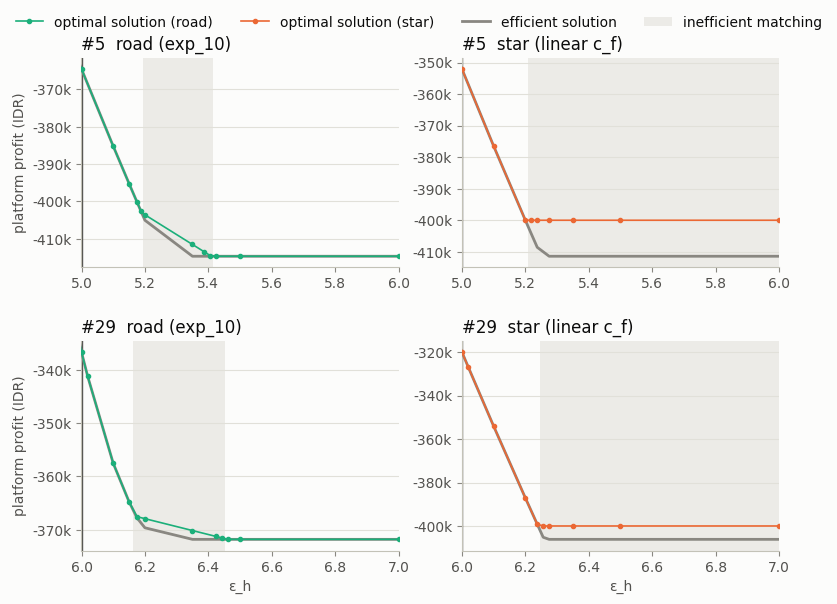

In [11]:
def shade_matched(ax, g):
    eps = g["eps_h"].to_numpy()
    edges = np.concatenate([[eps[0]], (eps[1:] + eps[:-1]) / 2, [eps[-1]]])
    for (x0, x1), k in zip(zip(edges[:-1], edges[1:]), g["n_high"]):
        if k > 0:
            ax.axvspan(x0, x1, color=SHADE, linewidth=0, zorder=0)

ZOOM_BELOW_L = 0.0

# one row per instance: road (left) and star (right)
fig, axes = plt.subplots(len(SB_INSTANCES), 2, figsize=(9, 3.2 * len(SB_INSTANCES)), squeeze=False,
                         gridspec_kw={"hspace": 0.35})
for row, i in enumerate(SB_INSTANCES):
    x_lo = pred.loc[i, "L"] - ZOOM_BELOW_L
    for col, arm in enumerate(["road", "star"]):
        ax = axes[row, col]
        g_all = sb_points.query("instance == @i and arm == @arm")
        # keep the neighbouring solved point on each side so shading and lines reach the axes edge
        k0 = max(0, int(np.searchsorted(g_all["eps_h"].to_numpy(), x_lo)) - 1)
        g = g_all.iloc[k0:]
        x_hi = g_all["eps_h"].max()
        mi = sb_model.query("instance == @i and eps_h >= @x_lo")

        # levels
        shade_matched(ax, g)
        ax.axvline(pred.loc[i, "L"], color=INK_SECONDARY, linewidth=1.0, zorder=1)
        visible = [g.loc[g["eps_h"] >= x_lo, ["optimal", "efficient"]].to_numpy().ravel()]
        ax.plot(g["eps_h"], g["efficient"], color=EFFICIENT_COLOR, linewidth=2, zorder=3)
        ax.plot(g["eps_h"], g["optimal"], color=ARM_COLORS[arm], linewidth=1.2, marker="o", markersize=3, zorder=4)
        lo, hi = np.min(np.concatenate(visible)), np.max(np.concatenate(visible))
        pad = 0.06 * (hi - lo)
        ax.set_xlim(x_lo, x_hi)
        ax.set_ylim(lo - pad, hi + pad)
        ax.yaxis.set_major_formatter(thousands)
        ax.set_title(f"#{i}  {ARM_LABELS[arm]}", loc="left", color=INK)
        ax.grid(axis="y")
        ax.set_axisbelow(True)

    axes[row, 0].set_ylabel("platform profit (IDR)")

for ax in axes[-1]:
    ax.set_xlabel("ε_h")

fig.legend(handles=[
    Line2D([], [], color=ARM_COLORS["road"], marker="o", markersize=3, linewidth=1.2, label="optimal solution (road)"),
    Line2D([], [], color=ARM_COLORS["star"], marker="o", markersize=3, linewidth=1.2, label="optimal solution (star)"),
    Line2D([], [], color=EFFICIENT_COLOR, linewidth=2, label="efficient solution"),
    Patch(facecolor=SHADE, label="inefficient matching"),
], loc="lower center", bbox_to_anchor=(0.5, 0.905), ncol=4)
plt.savefig(FIG_DIR / "double_switchback_optimal_vs_efficient.png", bbox_inches="tight", dpi=300)
plt.show()

,instance,arm,points,eps_range,profit_slope_per_ton,farmer_payment_range,optimal_slope_per_ton,efficient_slope_per_ton
0,5,road,4,5.200-5.406,52997.1,0.0,-52997.1,-49862.2
1,5,star,6,5.219-6.000,-0.0,0.0,0.0,-4642.7
2,29,road,5,6.175-6.444,14863.4,0.0,-14863.4,-13346.8
3,29,star,5,6.256-7.000,0.0,0.0,0.0,-555.6


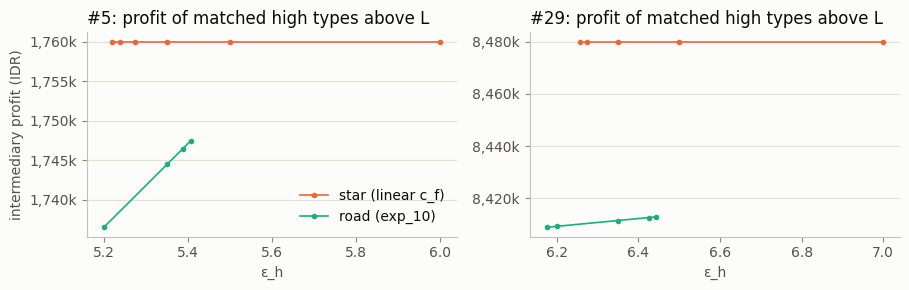

In [12]:
above = sb_points[(sb_points["n_high"] > 0) & (sb_points["eps_h"] > sb_points["instance"].map(pred["L"]))]
slopes = []
for (i, arm), g in above.groupby(["instance", "arm"]):
    if len(g) >= 2:
        slopes.append({
            "instance": i, "arm": arm, "points": len(g), "eps_range": f"{g.eps_h.min():.3f}-{g.eps_h.max():.3f}",
            "profit_slope_per_ton": np.polyfit(g.eps_h, g.high_profit, 1)[0],
            "farmer_payment_range": g.farmer_payments.max() - g.farmer_payments.min(),
            "optimal_slope_per_ton": np.polyfit(g.eps_h, g.optimal, 1)[0],
            "efficient_slope_per_ton": np.polyfit(g.eps_h, g.efficient, 1)[0],
        })
display(pd.DataFrame(slopes).round(1))

fig, axes = plt.subplots(1, len(SB_INSTANCES), figsize=(4.6 * len(SB_INSTANCES), 3.0), squeeze=False)
for ax, i in zip(axes.flat, SB_INSTANCES):
    for arm in ["star", "road"]:
        g = above.query("instance == @i and arm == @arm")
        ax.plot(g["eps_h"], g["high_profit"], color=ARM_COLORS[arm], linewidth=1.2, marker="o", markersize=3,
                label=ARM_LABELS[arm])
    ax.yaxis.set_major_formatter(thousands)
    ax.set_title(f"#{i}: profit of matched high types above L", loc="left", color=INK)
    ax.set_xlabel("ε_h")
    ax.grid(axis="y")
    ax.set_axisbelow(True)
axes.flat[0].set_ylabel("intermediary profit (IDR)")
axes.flat[0].legend(loc="best")
plt.tight_layout()
plt.savefig(FIG_DIR / "double_switchback_profit_above_L.png", bbox_inches="tight", dpi=300)
plt.show()

In [13]:
DEVIATIONS_PATH = Path("../results/exp_11/deviations.json")
if not DEVIATIONS_PATH.exists():
    subprocess.run([sys.executable, "deviation_analysis.py"], check=True)
    
reconstruction = json.loads(DEVIATIONS_PATH.read_text())

deviations = pd.DataFrame(reconstruction["deviations"])
deviations["worst_case_mix"] = deviations["worst_case_mix"].map(
    lambda mix: " + ".join(f"{m['weight']:.2f}×[{m['intermediary']:g} intermediary, {m['out']:g} out]" for m in mix))
deviations = deviations.sort_values(["instance", "arm", "high_type", "eps_h"]).reset_index(drop=True)
rel_err = (deviations["reconstructed_deviation"] - deviations["saved_profit"]).abs() / deviations["saved_profit"].abs().clip(lower=1)
print(f"reconstructed deviation vs saved profit: max relative error {rel_err.max():.1e} over {len(deviations)} points")

# eta against the measured profit slope above L (per instance, arm, high type)
eta_check = []
for (i, arm, h), g in deviations.groupby(["instance", "arm", "high_type"]):
    slope = np.polyfit(g.eps_h, g.saved_profit, 1)[0] if g.eps_h.nunique() > 1 else np.nan
    eta_check.append({"instance": i, "arm": arm, "high_type": h, "points": len(g),
                      "eta_min": g.eta.min(), "eta_max": g.eta.max(), "profit_slope_per_ton": slope})
display(pd.DataFrame(eta_check).round(1))
deviations.round({"eps_h": 4, "saved_profit": 0, "reconstructed_deviation": 0, "eta": 0})

reconstructed deviation vs saved profit: max relative error 2.8e-14 over 30 points


,instance,arm,high_type,points,eta_min,eta_max,profit_slope_per_ton
0,5,road,dreamy_hamilton,4,52997.1,52997.1,52997.1
1,5,star,dreamy_hamilton,6,0.0,0.0,-0.0
2,29,road,competent_wing,5,14863.4,14863.4,14863.4
3,29,road,zen_gauss,5,0.0,0.0,-0.0
4,29,star,competent_wing,5,0.0,0.0,0.0
5,29,star,zen_gauss,5,0.0,0.0,0.0


,instance,arm,high_type,eps_h,saved_profit,reconstructed_deviation,eta,worst_case_mix
0,5,road,dreamy_hamilton,5.2000,1736521.0,1736521.0,52997.0,"0.80×[2 intermediary, 5 out] + 0.20×[1 interme..."
1,5,road,dreamy_hamilton,5.3500,1744470.0,1744470.0,52997.0,"0.65×[2 intermediary, 5 out] + 0.35×[1 interme..."
2,5,road,dreamy_hamilton,5.3875,1746458.0,1746458.0,52997.0,"0.61×[2 intermediary, 5 out] + 0.39×[1 interme..."
3,5,road,dreamy_hamilton,5.4062,1747451.0,1747451.0,52997.0,"0.59×[2 intermediary, 5 out] + 0.41×[1 interme..."
4,5,star,dreamy_hamilton,5.2188,1760000.0,1760000.0,0.0,"1.00×[2 intermediary, 5 out]"
5,5,star,dreamy_hamilton,5.2375,1760000.0,1760000.0,0.0,"1.00×[2 intermediary, 5 out]"
6,5,star,dreamy_hamilton,5.2750,1760000.0,1760000.0,0.0,"1.00×[2 intermediary, 5 out]"
7,5,star,dreamy_hamilton,5.3500,1760000.0,1760000.0,0.0,"1.00×[2 intermediary, 5 out]"
8,5,star,dreamy_hamilton,5.5000,1760000.0,1760000.0,0.0,"1.00×[2 intermediary, 5 out]"
9,5,star,dreamy_hamilton,6.0000,1760000.0,1760000.0,0.0,"1.00×[2 intermediary, 5 out]"


In [14]:
def swap_table(swap):
    A, B = swap["A"], swap["B"]
    dropped, added = pd.DataFrame(swap["dropped"]), pd.DataFrame(swap["added"])
    table = pd.DataFrame({
        "": ["dropped (A only)", "added (B only)", "added − dropped"],
        "farmers": [f"{len(dropped)} ({int(dropped['intermediary'].sum())} intermediary)",
                    f"{len(added)} ({int((~added['intermediary']).sum())} outside)", ""],
        **{col: [dropped[col].sum(), added[col].sum(), added[col].sum() - dropped[col].sum()]
           for col in ["payment", "margin", "standalone_trip"]},
    })
    margin_gain = table.loc[2, "margin"]
    route_added = B["route_cost"] - A["route_cost"]
    gain = margin_gain - route_added
    print(f"#{swap['instance']} {swap['arm']}, {swap['high_type']}, ε_h = {swap['eps_h']:.3f}: η = {swap['eta']:,.0f}")
    print(f"  A: {A['intermediary']:g} intermediary + {A['out']:g} out, route cost {A['route_cost']:,.0f}, value {A['value']:,.0f}")
    print(f"  B: {B['intermediary']:g} intermediary + {B['out']:g} out, route cost {B['route_cost']:,.0f}, value {B['value']:,.0f}")
    print(f"  value of the swap = margin gained {margin_gain:,.0f} − route cost added {route_added:,.0f} = {gain:,.0f}, "
          f"per outside ton {gain / (B['out'] - A['out']):,.0f}")
    return table.round(0)

for swap in reconstruction["swaps"]:
    display(swap_table(swap))

#29 road, competent_wing, ε_h = 6.350: η = 14,863
  A: 7 intermediary + 6 out, route cost 1,202,831, value 4,151,102
  B: 0 intermediary + 13 out, route cost 1,246,397, value 4,255,146
  value of the swap = margin gained 147,609 − route cost added 43,566 = 104,044, per outside ton 14,863


,,farmers,payment,margin,standalone_trip
0,dropped (A only),8 (7 intermediary),16336100.0,3767900.0,1744287.0
1,added (B only),8 (8 outside),16188491.0,3915509.0,3993085.0
2,added − dropped,,-147609.0,147609.0,2248798.0


#5 road, dreamy_hamilton, ε_h = 5.350: η = 52,997
  A: 2 intermediary + 5 out, route cost 759,122, value 1,725,921
  B: 1 intermediary + 6 out, route cost 834,793, value 1,778,919
  value of the swap = margin gained 128,667 − route cost added 75,670 = 52,997, per outside ton 52,997


,,farmers,payment,margin,standalone_trip
0,dropped (A only),1 (1 intermediary),2058062.0,454938.0,100906.0
1,added (B only),1 (1 outside),1929394.0,583606.0,312840.0
2,added − dropped,,-128667.0,128667.0,211933.0


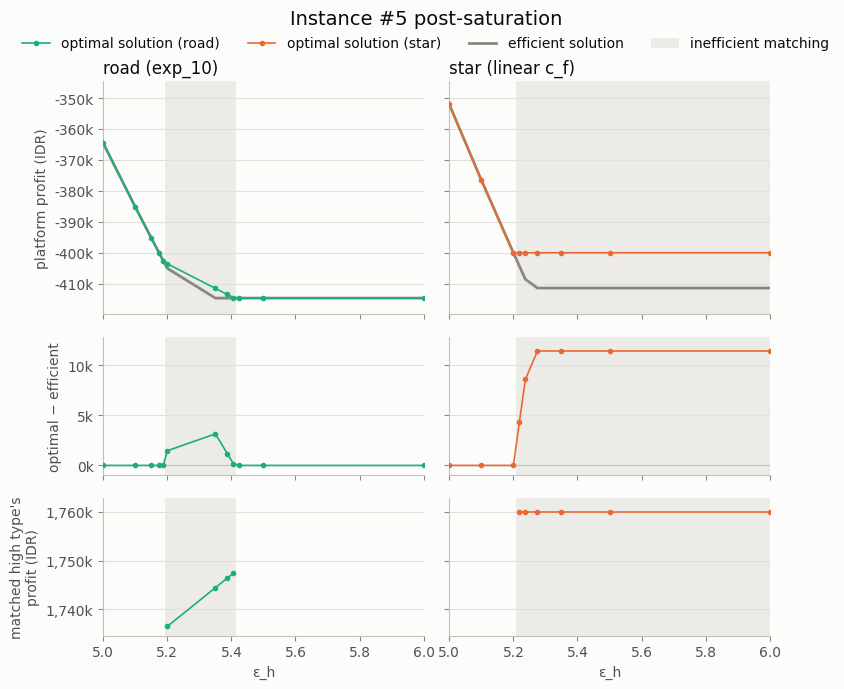

In [15]:
SUMMARY_INSTANCE = 5
i = SUMMARY_INSTANCE
x_lo = pred.loc[i, "L"]
eta_by_arm = deviations.query("instance == @i").groupby("arm")["eta"].median()

fig, axes = plt.subplots(3, 2, figsize=(8.6, 7.2), sharex="col", sharey="row",
                         gridspec_kw={"height_ratios": [2.2, 1.3, 1.3], "hspace": 0.14, "wspace": 0.08})
for col, arm in enumerate(["road", "star"]):
    g_all = sb_points.query("instance == @i and arm == @arm")
    k0 = max(0, int(np.searchsorted(g_all["eps_h"].to_numpy(), x_lo)) - 1)
    g = g_all.iloc[k0:]
    matched = g[g["n_high"] > 0]
    ax_lvl, ax_gap, ax_profit = axes[:, col]
    for ax in axes[:, col]:
        shade_matched(ax, g)
        ax.grid(axis="y")
        ax.set_axisbelow(True)

    # levels
    ax_lvl.plot(g["eps_h"], g["efficient"], color=EFFICIENT_COLOR, linewidth=2, zorder=3)
    ax_lvl.plot(g["eps_h"], g["optimal"], color=ARM_COLORS[arm], linewidth=1.2, marker="o", markersize=3, zorder=4)
    ax_lvl.set_title(ARM_LABELS[arm], loc="left", color=INK)

    # gap
    ax_gap.axhline(0, color=AXIS, linewidth=0.8, zorder=1)
    ax_gap.plot(g["eps_h"], g["value_of_matching_high"], color=ARM_COLORS[arm], linewidth=1.2,
                marker="o", markersize=3, zorder=4)

    # profit of the matched high type, only where it is matched; one line per contiguous run of
    # matched points (sb_points is sorted by instance, arm, eps_h, so consecutive rows are neighbours)
    runs_of_matched = (matched.index.to_series().diff() != 1).cumsum()
    for _, seg in matched.groupby(runs_of_matched):
        ax_profit.plot(seg["eps_h"], seg["high_profit"], color=ARM_COLORS[arm], linewidth=1.2, marker="o", markersize=3, zorder=4)
    eta = eta_by_arm.get(arm, np.nan)
    eta_label = "0" if abs(eta) < 0.5 else f"{eta / 1e3:,.1f}k per ton"
    ax_profit.set_xlabel("ε_h")
    ax_profit.set_xlim(x_lo, g_all["eps_h"].max())

# shared y-ranges, fitted to what is visible past L
def fit_ylim(ax_row, values, lower_pad=0.08, upper_pad=0.12, floor=None):
    lo, hi = np.nanmin(values), np.nanmax(values)
    if floor is not None:
        lo = min(lo, floor)
    span = hi - lo if hi > lo else max(1.0, abs(hi))
    ax_row.set_ylim(lo - lower_pad * span, hi + upper_pad * span)

window = sb_points.query("instance == @i and eps_h >= @x_lo")
fit_ylim(axes[0, 0], np.concatenate([window["optimal"], window["efficient"]]))
fit_ylim(axes[1, 0], window["value_of_matching_high"], floor=0.0)
fit_ylim(axes[2, 0], window.loc[window["n_high"] > 0, "high_profit"])
for ax, label, fmt in [(axes[0, 0], "platform profit (IDR)", thousands),
                       (axes[1, 0], "optimal − efficient", thousands),
                       (axes[2, 0], "matched high type's\nprofit (IDR)", thousands)]:
    ax.set_ylabel(label)
    ax.yaxis.set_major_formatter(fmt)

fig.legend(handles=[
    Line2D([], [], color=ARM_COLORS["road"], marker="o", markersize=3, linewidth=1.2, label="optimal solution (road)"),
    Line2D([], [], color=ARM_COLORS["star"], marker="o", markersize=3, linewidth=1.2, label="optimal solution (star)"),
    Line2D([], [], color=EFFICIENT_COLOR, linewidth=2, label="efficient solution"),
    Patch(facecolor=SHADE, label="inefficient matching"),
], loc="lower center", bbox_to_anchor=(0.5, 0.905), ncol=4)
fig.suptitle(f"Instance #{i} post-saturation", fontsize=14, color=INK)
plt.savefig(FIG_DIR / f"double_switchback_mechanism_{i}.png", bbox_inches="tight", dpi=300)
plt.show()